# ChessGPT — v4: a GPT from scratch, with attention maps

## Where we are
| Version | Model | Context | Bits/char | Legal move rate | Self-play plies |
|---|---|---|---|---|---|
| — | Frequency baseline | none | — | 11.2% | — |
| v1 | Bigram | 1 char | 2.430 | 10.2% | 0.31 |
| v2 | MLP + embeddings | 16 chars | 1.558 | 36.9% | 6.58 |
| v3 | LSTM | whole game (in a state of 384 numbers) | 1.258 | 55.4% | 10.43 |

The LSTM remembers the whole game, but only through **one state vector**, updated one character at a time. Its typical mistakes are plausible moves for pieces that are no longer where the model thinks they are: the picture of the board gets blurred.

## The idea of v4
A **Transformer** (Vaswani et al., 2017), in the decoder-only form used by GPT (Radford et al., 2018-2019). Instead of carrying everything in one state, at every position it can **look back directly at any earlier character** through **self-attention**, and decide by itself which ones matter.
When it writes `N`, it can go back and read the moves that brought that knight where it is now.

## What is new in v4
- **Self-attention**: queries, keys, values, scaled dot product, causal mask.
- **Multi-head attention**, **positional embeddings**, **Transformer blocks** with residual connections, LayerNorm and an MLP.
- Training **in parallel** over all positions: no sequential loop over time any more.
- AdamW with **weight decay on the weight matrices only**, and a learning rate with **warmup** and cosine decay.
- **Attention maps**: where does each head look? Does the model look at the earlier moves of the same piece?
- The **KV cache**: the trick that makes generation fast in real LLMs.

## Requirements and time
Run `chessgpt_v1.ipynb` first (cleaned games). The training cell prints the measured time per step after 20 steps, with a projection of the total: expect roughly **30–60 minutes** on an Apple M1. To make it faster, reduce `STEPS` in Step 4.

**Memory.** Attention stores a $T \times T$ matrix per head, so a Transformer needs much more memory than the LSTM. The notebook is set up for a Mac with **8 GB**: small micro-batches with gradient accumulation (Step 4), and a memory cap so that PyTorch raises an error instead of freezing the computer. Close other heavy apps (browser tabs, video) while training. If you still get an out-of-memory error, set `MICRO_BATCH = 4` and `ACCUM = 8` in Step 4.

In [1]:
# --- CORE LIBRARIES ---

# PyTorch: tensors, automatic gradients, neural networks.
import torch

# Neural network layers (Embedding, Linear, LayerNorm).
import torch.nn as nn

# Functional operations: softmax, cross-entropy.
import torch.nn.functional as F

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# python-chess: rules, legal moves, SAN parsing.
import chess

# SVG drawings of chess boards.
import chess.svg

# Display SVG images in the notebook.
from IPython.display import SVG, display

# Counting occurrences.
from collections import Counter

# File and folder paths.
from pathlib import Path

# Square root and cosine for the attention scale and the learning-rate schedule.
import math

# Regular expressions (SAN grammar).
import re

# Measure execution time.
import time

# Python's random module.
import random

# Shared results file.
import json

# Independent copies of objects (CPU copy of the model).
import copy

In [2]:
# --- DEVICE, MEMORY CAP AND REPRODUCIBILITY ---

# Fastest device available: NVIDIA GPU, Apple Silicon GPU, or CPU.
if torch.cuda.is_available():

    # NVIDIA GPU.
    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    # Apple Silicon GPU.
    device = torch.device("mps")

    # Cap PyTorch at 70% of the memory macOS recommends for the GPU: by default PyTorch may go well beyond it,
    # and on an 8 GB Mac the system then starts swapping and freezes. With the cap, a too-large batch raises a clear error instead.
    torch.mps.set_per_process_memory_fraction(0.7)

else:

    # CPU (slow for this model).
    device = torch.device("cpu")

# Seed for PyTorch.
torch.manual_seed(42)

# Seed for Python's random module.
random.seed(42)

# Seed for NumPy.
np.random.seed(42)

# Print the device.
print("Device:", device)

Device: mps


## Step 1 — Same data, vocabulary and split as v1–v3

The games cleaned by v1, the same 29-character vocabulary, the same split (seed 42), and later the same 1,000 test positions (seed 123). Every number in this notebook is directly comparable with the previous versions.

In [3]:
# --- LOAD THE CLEANED GAMES FROM v1 ---

# Folder with the chess data.
DATA_DIR = Path("data/lichess")

# File written by v1.
GAMES_PATH = DATA_DIR / "games_2013-01.txt"

# Stop if v1 has not been run.
assert GAMES_PATH.exists(), "Run chessgpt_v1.ipynb first."

# One game per line.
games = GAMES_PATH.read_text(encoding="utf-8").split("\n")

# --- SAME VOCABULARY ---

# Start/end-of-game token.
SEP = ";"

# Same sorted characters.
chars = sorted(set("".join(games)) | {SEP})

# Vocabulary size (29).
V = len(chars)

# Character -> index.
stoi = {c: i for i, c in enumerate(chars)}

# Index -> character.
itos = {i: c for c, i in stoi.items()}

# --- SAME SPLIT ---

# Copy of the games.
shuffled = games[:]

# Same shuffle (seed 42).
random.Random(42).shuffle(shuffled)

# 5% validation, 5% test.
n_val = n_test = len(shuffled) // 20

# Validation games.
val_games = shuffled[:n_val]

# Test games.
test_games = shuffled[n_val:n_val + n_test]

# Training games.
train_games = shuffled[n_val + n_test:]

# Checks.
print(f"Vocabulary: {V} | Train: {len(train_games):,} | Validation: {len(val_games):,} | Test: {len(test_games):,}")

# --- FAST ENCODING ---

# Byte value -> vocabulary index.
lookup = np.full(256, -1, dtype=np.int64)

# Fill the table.
for c, i in stoi.items():

    # One entry per character.
    lookup[ord(c)] = i


# Encode a string into vocabulary indices.
def encode(text):
    """String -> int64 NumPy array of vocabulary indices."""

    # Raw bytes through the lookup table.
    ids = lookup[np.frombuffer(text.encode("ascii"), dtype=np.uint8)]

    # Safety check.
    assert (ids >= 0).all()

    # Return the indices.
    return ids

Vocabulary: 29 | Train: 104,066 | Validation: 5,781 | Test: 5,781


## Step 2 — Training windows from the stream, whole games for validation

### Training: random windows of 512 characters
A Transformer reads a **block** of at most $T_{\max}$ characters at once: here $T_{\max} = 512$, about 124 plies, which covers the whole game for the vast majority of positions.

As in v3, all training games are joined into one long text, `;g1;g2;g3;…;`. Each training example is a **window of 513 consecutive characters** starting at a random point:

$$
x = (c_s, \dots, c_{s+511}), \qquad y = (c_{s+1}, \dots, c_{s+512}), \qquad s \sim \mathcal{U}\{0, \dots, N - 513\}
$$

The model predicts **all 512 next characters at once**: every position of the window is a training example, each one seeing only the characters before it (the causal mask of Step 3).
A window can start in the middle of a game and contain the end of one game and the beginning of the next. The model must learn that `;` means "new game": nothing before it matters any more. Attention can learn that easily, by simply not looking past the last `;`.

### Validation: whole games
Exactly as in v3, every validation game is evaluated separately, from its first character, with padding and a masked loss, so the bits per character are comparable.
A game longer than 512 characters (about 5% of them) does not fit in one block. For those we use a **sliding window**: blocks of 512 characters moving forward by 128, keeping only the predictions of the new characters, so every prediction still sees at least 384 characters of context.

### Where the data lives
As in v3, the data stays on the **CPU** (it avoids an `mps` bug with slices of large `uint8` tensors); only the current batch is copied to the GPU.

In [4]:
# --- TRAINING STREAM AND RANDOM WINDOWS ---

# Maximum context of the Transformer, in characters (about 124 plies).
BLOCK = 512

# All training games in one text: ';' + games separated by ';' + ';' (the same text as v1-v3), kept on the CPU.
train_data = torch.from_numpy(encode(SEP + SEP.join(train_games) + SEP).astype(np.uint8))

# Offsets 0, 1, ..., BLOCK inside a window (BLOCK + 1 characters: inputs plus the last target).
window_offsets = torch.arange(BLOCK + 1)

# Summary.
print(f"Training stream: {len(train_data):,} characters | windows of {BLOCK} characters")


# A batch of random windows.
def get_batch(batch_size):
    """Return inputs and targets of shape (batch_size, BLOCK) on the device; targets are shifted by one character."""

    # Random start of every window (the window must fit inside the stream).
    starts = torch.randint(0, len(train_data) - BLOCK - 1, (batch_size,))

    # Character indices of every window: starts as a column + offsets as a row -> (batch_size, BLOCK + 1).
    window = train_data[starts[:, None] + window_offsets].long()

    # Inputs: the first BLOCK characters; targets: the last BLOCK characters; both sent to the device.
    return window[:, :-1].to(device), window[:, 1:].to(device)


# Example batch of 2 windows.
x_ex, y_ex = get_batch(2)

# Check the shift: the target at position t is the input at position t + 1.
assert (x_ex[:, 1:] == y_ex[:, :-1]).all()

# First 70 characters of the first window.
print("input :", "".join(itos[i] for i in x_ex[0, :70].tolist()))

# The corresponding targets.
print("target:", "".join(itos[i] for i in y_ex[0, :70].tolist()))

# --- VALIDATION: WHOLE GAMES IN A PADDED MATRIX (as in v3) ---

# Padding value in the byte matrix (not a vocabulary index).
PAD = 255


# Build a padded byte matrix with one row per game: ';' + game + ';'.
def build_matrix(game_list):
    """Return (uint8 matrix N x L, lengths N) where lengths count the valid tokens of each row."""

    # Encoded rows: start token + game + end token.
    rows = [encode(SEP + g + SEP).astype(np.uint8) for g in game_list]

    # Number of valid tokens of each row.
    lengths = np.array([len(r) for r in rows])

    # Matrix filled with the padding value, as wide as the longest row.
    matrix = np.full((len(rows), lengths.max()), PAD, dtype=np.uint8)

    # Copy each row to the left of its line.
    for i, r in enumerate(rows):

        # Valid tokens first, padding after.
        matrix[i, :len(r)] = r

    # Return both.
    return matrix, lengths


# Validation matrix (full games), kept on the CPU.
val_matrix, val_lengths = build_matrix(val_games)

# As tensors.
val_matrix_t = torch.from_numpy(val_matrix)

# Lengths.
val_lengths_t = torch.from_numpy(val_lengths)

# Shape and share of games longer than one block.
print(f"Validation matrix: {val_matrix.shape} | games longer than {BLOCK} characters: {(val_lengths - 1 > BLOCK).mean():.1%}")


# Turn selected rows of a byte matrix into (inputs, targets).
def make_batch(matrix_t, lengths_t, rows):
    """rows: tensor of row indices. Returns inputs (B, L-1) and targets (B, L-1) with -100 on padding, on the device."""

    # Length of the longest selected game: columns beyond it are padding for every row.
    L = int(lengths_t[rows].max())

    # Selected rows, as int64 indices (built on the CPU).
    seq = matrix_t[rows, :L].long()

    # Inputs: all tokens but the last; padding replaced by ';' (any valid index works: it only comes AFTER the real characters).
    inputs = seq[:, :-1].masked_fill(seq[:, :-1] == PAD, stoi[SEP])

    # Targets: all tokens but the first; padding replaced by -100 so the loss ignores it.
    targets = seq[:, 1:].masked_fill(seq[:, 1:] == PAD, -100)

    # Send both to the device.
    return inputs.to(device), targets.to(device)

Training stream: 30,128,102 characters | windows of 512 characters
input :  Qh7#;e4 c5 Nf3 e6 d4 cxd4 Nxd4 a6 c4 Nf6 Nc3 Nc6 f3 Qb6 Nxc6 bxc6 Qe2
target: Qh7#;e4 c5 Nf3 e6 d4 cxd4 Nxd4 a6 c4 Nf6 Nc3 Nc6 f3 Qb6 Nxc6 bxc6 Qe2 
Validation matrix: (5781, 1052) | games longer than 512 characters: 6.2%


## Step 3 — The model: a GPT from scratch

### 1. Tokens and positions
Every character $c_t$ becomes the sum of a **token embedding** and a **position embedding**:

$$
x_t = E[c_t] + P[t], \qquad E \in \mathbb{R}^{29 \times d}, \quad P \in \mathbb{R}^{512 \times d}, \quad d = 192
$$

Attention, as we will see, treats its inputs as a *set*: without $P$ the model could not tell `e4 e5` from `e5 e4`. The positions are learned like any other weight.

### 2. Self-attention: every character asks a question
From each $x_t$ three vectors are computed with three learned matrices:

$$
q_t = W_Q\, x_t \ \ (\text{query: what am I looking for?}),
\qquad
k_j = W_K\, x_j \ \ (\text{key: what do I contain?}),
\qquad
v_j = W_V\, x_j \ \ (\text{value: what do I pass on?})
$$

The character at position $t$ compares its query with the keys of all characters $j \le t$, turns the scores into weights with a softmax, and takes the weighted average of their values:

$$
s_{t,j} = \frac{q_t \cdot k_j}{\sqrt{d_k}},
\qquad
\alpha_{t,j} = \frac{e^{s_{t,j}}}{\sum_{j' \le t} e^{s_{t,j'}}},
\qquad
y_t = \sum_{j \le t} \alpha_{t,j}\, v_j
$$

The weights $\alpha_{t,j}$ are the **attention map**: how much position $t$ looks at position $j$. In matrix form, for the whole sequence at once:

$$
\text{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{Q K^\top}{\sqrt{d_k}} + M\right) V,
\qquad
M_{t,j} = \begin{cases} 0 & j \le t \\ -\infty & j > t \end{cases}
$$

- The **causal mask** $M$ forbids looking at the future: $e^{-\infty} = 0$. This is what lets us train all 512 positions at once without cheating.
- **Why $\sqrt{d_k}$?** If $q$ and $k$ have independent components with variance 1, their dot product has variance $d_k$. Without the division, the scores would be large, the softmax would saturate on one position and its gradients would vanish.

### 3. Multi-head attention
One attention can only compute one weighted average per position. We run $h = 6$ attentions in parallel (**heads**), each with $d_k = d / h = 32$ dimensions, and concatenate their outputs:

$$
\text{MHA}(X) = \big[\text{head}_1, \dots, \text{head}_6\big]\, W_O
$$

Each head can specialise: one may look at the previous character, another at the start of the current move, another at the earlier moves of the same piece.

### 4. The Transformer block
$$
\begin{aligned}
x &\leftarrow x + \text{MHA}\big(\text{LN}(x)\big) && \text{communication: positions exchange information} \\
x &\leftarrow x + \text{MLP}\big(\text{LN}(x)\big), \quad \text{MLP}(u) = W_2\, \text{GELU}(W_1 u) && \text{computation: each position thinks on its own}
\end{aligned}
$$

- The **residual connections** ($x \leftarrow x + \dots$) are the same idea as ResNet and as the LSTM cell state: an additive path along which information and gradients flow freely.
- **LayerNorm** normalises each position's vector to mean 0 and variance 1 (then rescales it with learned parameters), which keeps training stable. As in GPT-2, it is applied *before* each sub-layer ("pre-norm").
- The MLP expands to $4d = 768$ dimensions; GELU is a smooth version of ReLU.

We stack $L = 6$ blocks, then a final LayerNorm and a linear layer that produces the 29 logits.

### LSTM vs Transformer
| | LSTM (v3) | Transformer (v4) |
|---|---|---|
| Path between characters $t$ and $t - k$ | $k$ steps through the state | **1 step** (direct attention) |
| Training | sequential in time | **parallel** over all positions |
| Cost per sequence | $O(T)$ | $O(T^2)$ (every pair of positions): this is why the context is limited to 512 |
| Memory of the past | compressed in a fixed-size state | the whole context, re-read at every step |

### Initialisation (GPT-2)
All weights start from $\mathcal{N}(0, 0.02^2)$. The output projections of attention and MLP, which add into the residual path, use a smaller $0.02 / \sqrt{2L}$, so that the sum of $2L$ contributions does not grow with depth.

### The KV cache argument
The attention layer also accepts a **cache** of the keys and values already computed (used for fast generation in Step 7) and can return its attention maps (Step 6).

### Parameters
| Part | Computation | Parameters |
|---|---|---|
| Token embedding | $29 \times 192$ | 5,568 |
| Position embedding | $512 \times 192$ | 98,304 |
| One block: 2 LayerNorm | $2 \times 2 \times 192$ | 768 |
| One block: $W_Q, W_K, W_V$ (one matrix) | $192 \times 576 + 576$ | 111,168 |
| One block: $W_O$ | $192 \times 192 + 192$ | 37,056 |
| One block: MLP | $192 \times 768 + 768 + 768 \times 192 + 192$ | 295,872 |
| 6 blocks | $6 \times 444{,}864$ | 2,669,184 |
| Final LayerNorm + output layer | $384 + 192 \times 29 + 29$ | 5,981 |
| **Total** | | **2,779,037** |

About 1.5 times the LSTM (1,883,869): comparable sizes, very different architectures.

In [5]:
# --- THE MODEL ---

# Size of the vectors flowing through the network (d).
N_EMBD = 192

# Number of attention heads (each with N_EMBD / N_HEAD = 32 dimensions).
N_HEAD = 6

# Number of Transformer blocks.
N_LAYER = 6


# Multi-head causal self-attention.
class CausalSelfAttention(nn.Module):

    # Declare the weights.
    def __init__(self, n_embd, n_head):

        # Initialise the parent class.
        super().__init__()

        # The embedding size must split evenly into the heads.
        assert n_embd % n_head == 0

        # Number of heads.
        self.n_head = n_head

        # Dimensions per head (d_k).
        self.head_dim = n_embd // n_head

        # W_Q, W_K and W_V for all heads in one matrix: d -> 3d.
        self.qkv = nn.Linear(n_embd, 3 * n_embd)

        # Output projection W_O: d -> d.
        self.proj = nn.Linear(n_embd, n_embd)

    # Attention over a sequence (optionally continuing from cached keys and values).
    def forward(self, x, cache=None, return_attn=False):
        """x: (B, T, d). Returns output (B, T, d), the (keys, values) for a cache, and the attention map if asked."""

        # Batch size, new positions, embedding size.
        B, T, C = x.shape

        # Queries, keys and values of the new positions, each (B, T, d).
        q, k, v = self.qkv(x).split(C, dim=2)

        # Split d into heads and put the heads first: (B, T, d) -> (B, T, H, d_k) -> (B, H, T, d_k).
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Same for the keys.
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Same for the values.
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # With a cache: prepend the keys and values of the positions already processed.
        if cache is not None:

            # Old keys + new keys along the time axis.
            k = torch.cat([cache[0], k], dim=2)

            # Old values + new values.
            v = torch.cat([cache[1], v], dim=2)

        # Total number of positions that can be looked at (old + new).
        T_k = k.shape[2]

        # Scores q . k / sqrt(d_k) for every pair (new position, any position): (B, H, T, T_k).
        # Dividing q (small) instead of the score matrix (large) gives the same result and saves one big T x T tensor.
        att = (q / math.sqrt(self.head_dim)) @ k.transpose(-2, -1)

        # Absolute position of every query: the new positions are the last T of the T_k.
        query_pos = torch.arange(T, device=x.device)[:, None] + (T_k - T)

        # Absolute position of every key.
        key_pos = torch.arange(T_k, device=x.device)[None, :]

        # Causal mask: a query may look at keys at its own position or before (True = allowed).
        allowed = key_pos <= query_pos

        # Forbidden scores become -infinity, i.e. weight 0 after the softmax ("_": in place, again to save memory).
        att.masked_fill_(~allowed, float("-inf"))

        # Attention weights alpha: each row sums to 1.
        att = F.softmax(att, dim=-1)

        # Weighted average of the values: (B, H, T, T_k) @ (B, H, T_k, d_k) -> (B, H, T, d_k).
        y = att @ v

        # Put the heads back side by side: (B, H, T, d_k) -> (B, T, H, d_k) -> (B, T, d).
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        # Output projection, keys and values (for the cache), attention map (only if asked).
        return self.proj(y), (k, v), (att if return_attn else None)


# One Transformer block: communication (attention) + computation (MLP), each with a residual connection.
class Block(nn.Module):

    # Declare the sub-layers.
    def __init__(self, n_embd, n_head):

        # Initialise the parent class.
        super().__init__()

        # LayerNorm before attention.
        self.ln1 = nn.LayerNorm(n_embd)

        # Multi-head causal self-attention.
        self.attn = CausalSelfAttention(n_embd, n_head)

        # LayerNorm before the MLP.
        self.ln2 = nn.LayerNorm(n_embd)

        # MLP: d -> 4d -> GELU -> d.
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd))

    # Forward pass of the block.
    def forward(self, x, cache=None, return_attn=False):

        # Attention on the normalised input.
        a, kv, att = self.attn(self.ln1(x), cache, return_attn)

        # Residual connection around attention.
        x = x + a

        # Residual connection around the MLP.
        x = x + self.mlp(self.ln2(x))

        # New representation, keys/values, attention map.
        return x, kv, att


# The full character-level GPT.
class GPT(nn.Module):

    # Declare the layers.
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer):

        # Initialise the parent class.
        super().__init__()

        # Maximum context length.
        self.block_size = block_size

        # Token embedding E: one vector per character.
        self.tok_emb = nn.Embedding(vocab_size, n_embd)

        # Position embedding P: one vector per position 0..block_size-1.
        self.pos_emb = nn.Embedding(block_size, n_embd)

        # The stack of Transformer blocks.
        self.blocks = nn.ModuleList([Block(n_embd, n_head) for _ in range(n_layer)])

        # Final LayerNorm.
        self.ln_f = nn.LayerNorm(n_embd)

        # Output layer: one logit per possible next character.
        self.head = nn.Linear(n_embd, vocab_size)

        # GPT-2 initialisation of every Linear and Embedding layer.
        self.apply(self._init_weights)

        # Smaller initialisation for the projections that add into the residual path.
        for name, p in self.named_parameters():

            # W_O of attention and the second linear layer of the MLP.
            if name.endswith("attn.proj.weight") or name.endswith("mlp.2.weight"):

                # Standard deviation 0.02 / sqrt(2L).
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    # Initialisation rule for one module.
    def _init_weights(self, module):

        # Linear layers.
        if isinstance(module, nn.Linear):

            # Weights from N(0, 0.02^2).
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

            # Biases at zero.
            if module.bias is not None:

                # Zero.
                nn.init.zeros_(module.bias)

        # Embedding tables.
        elif isinstance(module, nn.Embedding):

            # Vectors from N(0, 0.02^2).
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    # Forward pass.
    def forward(self, idx, cache=None, use_cache=False, return_attn=False):
        """idx: (B, T) character indices. Returns logits (B, T, V), the new cache (if use_cache), the attention maps (if return_attn)."""

        # Batch size and number of new positions.
        B, T = idx.shape

        # Positions already in the cache (0 without a cache).
        offset = 0 if cache is None else cache[0][0].shape[2]

        # The context must fit in the position table.
        assert offset + T <= self.block_size, "sequence longer than the context of the model"

        # Absolute positions of the new characters.
        pos = torch.arange(offset, offset + T, device=idx.device)

        # Token embedding + position embedding: (B, T, d) + (T, d) broadcast over the batch.
        x = self.tok_emb(idx) + self.pos_emb(pos)

        # Keys and values of every block (for the cache).
        new_cache = []

        # Attention map of every block.
        attn_maps = []

        # Through the blocks.
        for i, block in enumerate(self.blocks):

            # Block i, with its part of the cache if there is one.
            x, kv, att = block(x, None if cache is None else cache[i], return_attn)

            # Keep its keys and values.
            new_cache.append(kv)

            # Keep its attention map (None if not asked).
            attn_maps.append(att)

        # Final LayerNorm and output layer.
        logits = self.head(self.ln_f(x))

        # Logits, cache and attention maps (None when not asked for).
        return logits, (new_cache if use_cache else None), (attn_maps if return_attn else None)


# Create the model on the device.
model = GPT(V, BLOCK, N_EMBD, N_HEAD, N_LAYER).to(device)

# Count the parameters: expected 2,779,037.
n_params = sum(p.numel() for p in model.parameters())

# Total.
print(f"Parameters: {n_params:,}")

# Quick check on the example batch: logits for every position.
logits_ex, _, _ = model(x_ex)

# Shape (2, 512, 29).
print("Logits shape:", tuple(logits_ex.shape))

# At initialisation the prediction is almost uniform: loss close to ln(29) = 3.37 nats.
print(f"Initial loss: {F.cross_entropy(logits_ex.reshape(-1, V), y_ex.reshape(-1)).item():.3f}  (uniform: {math.log(V):.3f})")

Parameters: 2,779,037
Logits shape: (2, 512, 29)
Initial loss: 3.353  (uniform: 3.367)


## Step 4 — Training: AdamW, warmup and cosine decay

| Setting | Value |
|---|---|
| Batch | 4 micro-batches $\times$ 8 windows $\times$ 512 characters = 16,384 predictions per step |
| Steps | 3,000, i.e. about 49 million characters, about 1.6 passes over the training stream |
| Optimizer | AdamW, $\beta = (0.9, 0.99)$, weight decay 0.1 on weight matrices only |
| Learning rate | linear warmup to $10^{-3}$ in 200 steps, then cosine decay to $10^{-4}$ |
| Gradient clipping | maximum norm 1.0 |

### Gradient accumulation: a big batch on a small GPU
The attention matrices of one step take memory proportional to $B \times H \times T^2$: with 32 windows of 512 characters, about 200 MB **per matrix**, several per layer, too much for an 8 GB Mac. But the gradient of a mean is the mean of the gradients, so a batch of 32 windows can be split into $A = 4$ **micro-batches** of 8:

$$
\nabla_\theta \frac{1}{A} \sum_{a=1}^{A} L_a = \frac{1}{A} \sum_{a=1}^{A} \nabla_\theta L_a
$$

For each micro-batch we compute $L_a / A$ and call `backward()`: PyTorch **adds** the new gradients to those already stored in `.grad`. After the $A$ micro-batches, `.grad` holds exactly the gradient of the full batch, and only then do we clip and update. Same result as a batch of 32, a quarter of the memory, about the same time.

### Weight decay on matrices only
Weight decay pulls every decayed parameter towards 0 at each step:

$$
\theta \leftarrow \theta - \eta\,\lambda\,\theta \quad (\text{plus the usual Adam update})
$$

This is useful for the large weight matrices (it keeps them small and the model smoother), but not for **biases** and **LayerNorm gains**: pulling a LayerNorm gain towards 0 would switch the layer off. So we split the parameters in two groups: tensors with 2 or more dimensions (matrices and embedding tables) get $\lambda = 0.1$, vectors get $\lambda = 0$.

### Warmup
At the start, the weights are random and Adam's estimates of the gradient statistics are based on very few steps, so large updates can push the network into a bad region. The learning rate grows linearly for the first $W = 200$ steps, then follows a cosine:

$$
\eta(s) =
\begin{cases}
\eta_{\max}\, \dfrac{s}{W} & s < W \\[2mm]
\eta_{\min} + \tfrac{1}{2}(\eta_{\max} - \eta_{\min})\left(1 + \cos\!\left(\pi\, \dfrac{s - W}{S - W}\right)\right) & s \ge W
\end{cases}
$$

### No dropout
With about 30 million training characters, a model of 2.8 million parameters and only about 1.6 passes over the data, overfitting is not a risk (in v3, train and validation stayed within 0.04 bits per character). We therefore use no dropout.

### Evaluation
Every 250 steps: 512 fixed whole validation games. At the end: all 5,781 games, with the sliding window for the long ones (Step 2). After 20 steps the cell prints the measured time per step and the projected total.

1.00 s/step -> about 50 minutes for 3,000 steps (plus evaluations)
step   250/3000 | train 2.515 bpc | val 2.170 bpc | grad norm 0.90 | lr 1.0e-03 | 207s
step   500/3000 | train 1.989 bpc | val 1.877 bpc | grad norm 0.54 | lr 9.7e-04 | 428s
step   750/3000 | train 1.791 bpc | val 1.749 bpc | grad norm 0.50 | lr 9.2e-04 | 668s
step  1000/3000 | train 1.674 bpc | val 1.628 bpc | grad norm 0.46 | lr 8.3e-04 | 909s
step  1250/3000 | train 1.581 bpc | val 1.554 bpc | grad norm 0.44 | lr 7.2e-04 | 1167s
step  1500/3000 | train 1.513 bpc | val 1.490 bpc | grad norm 0.42 | lr 6.0e-04 | 1418s
step  1750/3000 | train 1.457 bpc | val 1.434 bpc | grad norm 0.42 | lr 4.7e-04 | 1689s
step  2000/3000 | train 1.414 bpc | val 1.394 bpc | grad norm 0.43 | lr 3.5e-04 | 1994s
step  2250/3000 | train 1.375 bpc | val 1.357 bpc | grad norm 0.43 | lr 2.5e-04 | 2256s
step  2500/3000 | train 1.349 bpc | val 1.332 bpc | grad norm 0.43 | lr 1.7e-04 | 2455s
step  2750/3000 | train 1.327 bpc | val 1.316 bpc | grad 

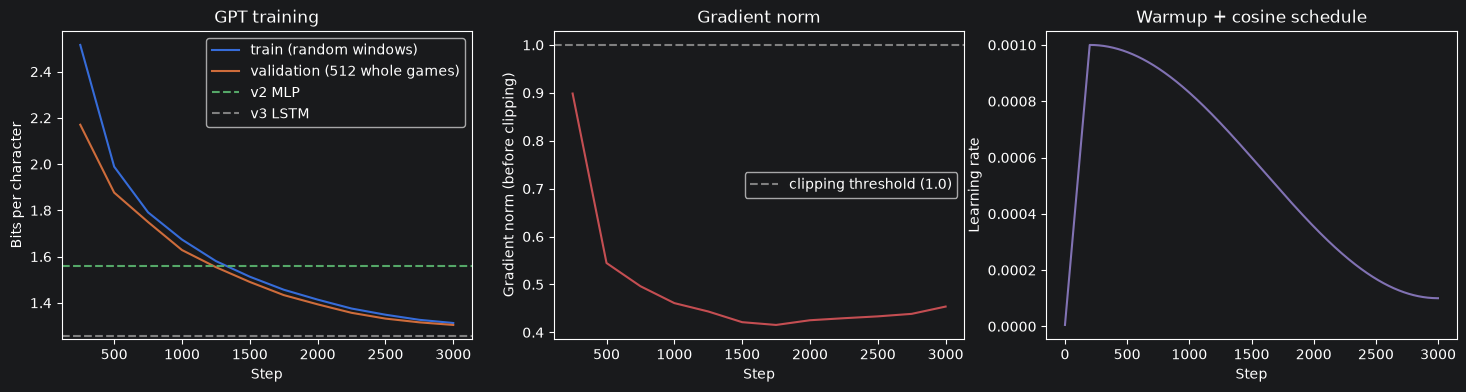

In [6]:
# --- TRAINING SETTINGS ---

# Optimisation steps (weight updates).
STEPS = 3000

# Windows per micro-batch: what is on the GPU at once (set 4 if the GPU runs out of memory).
MICRO_BATCH = 8

# Micro-batches per step: the effective batch is MICRO_BATCH * ACCUM = 32 windows (set 8 together with MICRO_BATCH = 4).
ACCUM = 4

# Peak learning rate.
LR_MAX = 1e-3

# Final learning rate.
LR_MIN = 1e-4

# Warmup steps.
WARMUP = 200

# Maximum gradient norm.
CLIP = 1.0

# Evaluate every EVAL_EVERY steps.
EVAL_EVERY = 250

# Shift of the sliding window for games longer than BLOCK.
STRIDE = 128

# --- OPTIMISER WITH TWO PARAMETER GROUPS ---

# Matrices and embedding tables (2 or more dimensions): with weight decay.
decay_params = [p for p in model.parameters() if p.dim() >= 2]

# Biases and LayerNorm parameters (1 dimension): without weight decay.
no_decay_params = [p for p in model.parameters() if p.dim() < 2]

# AdamW with the two groups.
optimizer = torch.optim.AdamW([{"params": decay_params, "weight_decay": 0.1},
                               {"params": no_decay_params, "weight_decay": 0.0}], lr=LR_MAX, betas=(0.9, 0.99))


# Learning-rate multiplier for step s (the scheduler multiplies LR_MAX by this value).
def lr_factor(s):
    """Linear warmup, then cosine decay from LR_MAX to LR_MIN."""

    # Warmup: grows linearly from 1/WARMUP to 1.
    if s < WARMUP:

        # Fraction of the warmup done.
        return (s + 1) / WARMUP

    # Progress of the cosine phase, from 0 to 1.
    progress = (s - WARMUP) / max(1, STEPS - WARMUP)

    # Cosine between 1 and LR_MIN / LR_MAX.
    return LR_MIN / LR_MAX + 0.5 * (1 - LR_MIN / LR_MAX) * (1 + math.cos(math.pi * progress))


# Scheduler applying lr_factor at every step.
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)


# Logits for sequences of any length: one block, or a sliding window for longer sequences.
@torch.no_grad()
def logits_long(x):
    """x: (B, T) inputs. Returns logits (B, T, V); beyond BLOCK every prediction sees at least BLOCK - STRIDE characters."""

    # Length of the sequences.
    T = x.shape[1]

    # Short enough: one forward pass.
    if T <= BLOCK:

        # Logits of every position.
        return model(x)[0]

    # Room for the logits of every position.
    logits = torch.empty(x.shape[0], T, V, device=device)

    # First block: the first BLOCK positions.
    logits[:, :BLOCK] = model(x[:, :BLOCK])[0]

    # Positions already predicted.
    done = BLOCK

    # Move the window forward until the end.
    while done < T:

        # End of the new window.
        end = min(done + STRIDE, T)

        # Its start: BLOCK characters before the end.
        start = end - BLOCK

        # Keep only the predictions of the positions not predicted yet.
        logits[:, done:end] = model(x[:, start:end])[0][:, done - start:]

        # Advance.
        done = end

    # All logits.
    return logits


# Exact loss on a set of whole validation games, plus the loss at every character position.
@torch.no_grad()
def eval_games(rows, batch=16):
    """Return (average NLL in nats, sum of NLL per position, count per position)."""

    # Evaluation mode.
    model.eval()

    # Sort the games by length, so that each batch contains games of similar length.
    rows = rows[torch.argsort(val_lengths_t[rows])]

    # Full width of the validation matrix.
    max_len = val_matrix_t.shape[1]

    # Sum of the losses at each position.
    pos_sum = torch.zeros(max_len - 1, device=device)

    # Number of real targets at each position.
    pos_count = torch.zeros(max_len - 1, device=device)

    # Go through the games in groups.
    for i in range(0, len(rows), batch):

        # Inputs and targets of this group.
        x, y = make_batch(val_matrix_t, val_lengths_t, rows[i:i + batch])

        # Logits of every position (sliding window if needed).
        logits = logits_long(x)

        # Loss of every single target; padding gives 0 thanks to ignore_index.
        losses = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=-100, reduction="none").view(y.shape)

        # Mask of the real targets.
        mask = (y != -100).float()

        # Width of this group.
        L = y.shape[1]

        # Accumulate per position.
        pos_sum[:L] += (losses * mask).sum(dim=0)

        # Count per position.
        pos_count[:L] += mask.sum(dim=0)

    # Back to training mode.
    model.train()

    # Give the cached GPU memory back (only on Apple GPUs).
    if device.type == "mps":

        # Release unused cached blocks.
        torch.mps.empty_cache()

    # Average NLL, and the per-position arrays on the CPU.
    return (pos_sum.sum() / pos_count.sum()).item(), pos_sum.cpu().numpy(), pos_count.cpu().numpy()


# 512 fixed validation games for the periodic evaluation.
val_sample_rows = torch.arange(512)

# History for the plots.
history = {"step": [], "train": [], "val": [], "grad_norm": [], "lr": []}

# Running sums kept on the GPU.
running_loss = torch.zeros((), device=device)

# Running sum of gradient norms.
running_norm = torch.zeros((), device=device)

# Start time.
start = time.perf_counter()

# Training mode.
model.train()

# Training loop.
for step in range(1, STEPS + 1):

    # Reset gradients once per step (they are accumulated over the micro-batches).
    optimizer.zero_grad(set_to_none=True)

    # Gradient accumulation over ACCUM micro-batches.
    for _ in range(ACCUM):

        # A micro-batch of random windows.
        x, y = get_batch(MICRO_BATCH)

        # Logits of all 512 positions of every window, in parallel.
        logits, _, _ = model(x)

        # Cross-entropy over all predictions, divided by ACCUM so that the summed gradients are a mean.
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1)) / ACCUM

        # Backpropagation: the gradients are ADDED to those already in .grad.
        loss.backward()

        # Accumulate the loss on the GPU (the ACCUM parts add up to the mean loss of the step).
        running_loss += loss.detach()

    # Clip the gradient norm; returns the norm before clipping.
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)

    # Update the weights.
    optimizer.step()

    # Update the learning rate.
    scheduler.step()

    # Accumulate the gradient norm.
    running_norm += norm.detach()

    # Early time check after 20 steps.
    if step == 20:

        # The GPU works asynchronously: wait until it has really finished before reading the clock.
        loss.item()

        # Seconds per step so far.
        per_step = (time.perf_counter() - start) / step

        # Projected total.
        print(f"{per_step:.2f} s/step -> about {per_step * STEPS / 60:.0f} minutes for {STEPS:,} steps (plus evaluations)")

    # Periodic evaluation.
    if step % EVAL_EVERY == 0:

        # Average training loss since the last evaluation.
        train_loss = running_loss.item() / EVAL_EVERY

        # Average gradient norm since the last evaluation.
        grad_norm = running_norm.item() / EVAL_EVERY

        # Reset the running sums.
        running_loss.zero_()

        # Same for the norm.
        running_norm.zero_()

        # Validation loss on the 512 fixed whole games.
        val_loss, _, _ = eval_games(val_sample_rows)

        # Store the step.
        history["step"].append(step)

        # Training loss.
        history["train"].append(train_loss)

        # Validation loss.
        history["val"].append(val_loss)

        # Gradient norm.
        history["grad_norm"].append(grad_norm)

        # Current learning rate.
        history["lr"].append(scheduler.get_last_lr()[0])

        # Progress line in bits per character.
        print(f"step {step:5d}/{STEPS} | train {train_loss / np.log(2):.3f} bpc | val {val_loss / np.log(2):.3f} bpc | "
              f"grad norm {grad_norm:.2f} | lr {history['lr'][-1]:.1e} | {time.perf_counter() - start:.0f}s")

# --- EXACT VALIDATION LOSS ON ALL GAMES ---

# All validation games.
nll_gpt, pos_sum, pos_count = eval_games(torch.arange(len(val_lengths_t)))

# Bits per character.
bpc_gpt = nll_gpt / np.log(2)

# Report with the previous versions.
print(f"\nValidation: {bpc_gpt:.3f} bits/char | perplexity {np.exp(nll_gpt):.2f}   (v1 bigram 2.430, v2 MLP 1.558, v3 LSTM 1.258)")

# --- TRAINING CURVES ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

# Training loss in bits per character.
ax1.plot(history["step"], np.array(history["train"]) / np.log(2), label="train (random windows)")

# Validation loss.
ax1.plot(history["step"], np.array(history["val"]) / np.log(2), label="validation (512 whole games)")

# v2 reference.
ax1.axhline(1.558, linestyle="--", color="#55A868", label="v2 MLP")

# v3 reference.
ax1.axhline(1.258, linestyle="--", color="gray", label="v3 LSTM")

# x-axis label.
ax1.set_xlabel("Step")

# y-axis label.
ax1.set_ylabel("Bits per character")

# Title.
ax1.set_title("GPT training")

# Legend.
ax1.legend()

# Gradient norm before clipping.
ax2.plot(history["step"], history["grad_norm"], color="#C44E52")

# Clipping threshold.
ax2.axhline(CLIP, linestyle="--", color="gray", label=f"clipping threshold ({CLIP})")

# x-axis label.
ax2.set_xlabel("Step")

# y-axis label.
ax2.set_ylabel("Gradient norm (before clipping)")

# Title.
ax2.set_title("Gradient norm")

# Legend.
ax2.legend()

# The full learning-rate schedule, computed from lr_factor.
ax3.plot(range(STEPS), [LR_MAX * lr_factor(s) for s in range(STEPS)], color="#8172B3")

# x-axis label.
ax3.set_xlabel("Step")

# y-axis label.
ax3.set_ylabel("Learning rate")

# Title.
ax3.set_title("Warmup + cosine schedule")

# Render.
plt.show()

## Step 5 — Loss along the game

The same diagnostic as v3: average loss at every position of the validation games, converted to plies (about 4.14 characters per ply).

$$
\bar{\ell}(t) = \frac{\sum_{g} m_{g,t}\, \ell_{g,t}}{\sum_{g} m_{g,t}}
$$

The dashed line marks the **context limit** of 512 characters: beyond it the model no longer sees the beginning of the game (sliding window). The v3 LSTM curve peaked at about 1.52 bits per character around ply 50. Where does the GPT gain the most?

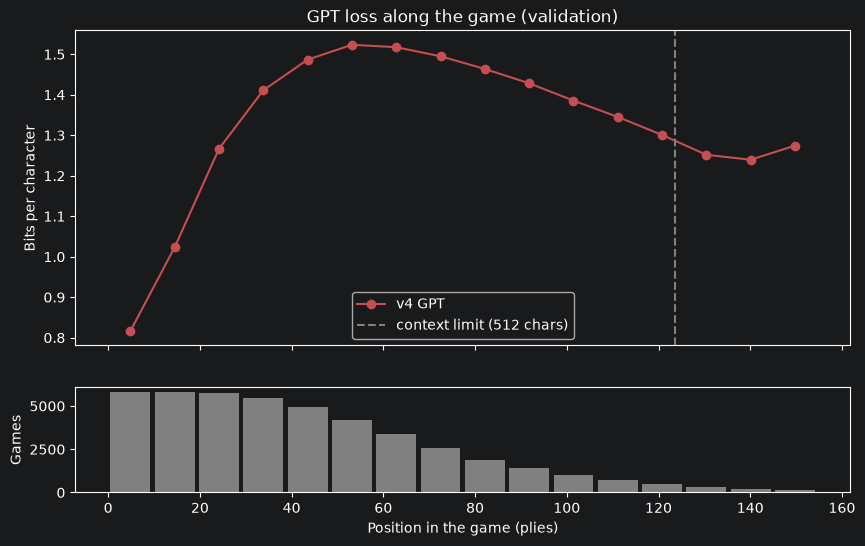

In [7]:
# --- LOSS AS A FUNCTION OF THE POSITION IN THE GAME ---

# Width of each bin, in characters.
BIN = 40

# Number of complete bins.
n_bins = len(pos_sum) // BIN

# Sum of the losses in each bin.
bin_sum = pos_sum[:n_bins * BIN].reshape(n_bins, BIN).sum(axis=1)

# Number of targets in each bin.
bin_count = pos_count[:n_bins * BIN].reshape(n_bins, BIN).sum(axis=1)

# Number of games still running at the start of each bin.
games_alive = pos_count[::BIN][:n_bins]

# Keep only bins with at least 100 games.
keep = games_alive >= 100

# Centre of each bin, in plies.
centres_plies = (np.arange(n_bins) * BIN + BIN / 2) / 4.14

# Two panels sharing the x-axis.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

# Average bits per character in each bin.
ax1.plot(centres_plies[keep], (bin_sum[keep] / bin_count[keep]) / np.log(2), marker="o", color="#C44E52", label="v4 GPT")

# Context limit, in plies.
ax1.axvline(BLOCK / 4.14, linestyle="--", color="gray", label=f"context limit ({BLOCK} chars)")

# y-axis label.
ax1.set_ylabel("Bits per character")

# Title.
ax1.set_title("GPT loss along the game (validation)")

# Legend.
ax1.legend()

# Bottom panel: how many games reach each point.
ax2.bar(centres_plies[keep], games_alive[keep], width=BIN / 4.14 * 0.9, color="gray")

# x-axis label.
ax2.set_xlabel("Position in the game (plies)")

# y-axis label.
ax2.set_ylabel("Games")

# Render.
plt.show()

## Step 6 — Attention maps: where does the model look?

The attention weights $\alpha_{t,j}$ are part of the computation itself, so we can simply read them. Three views:

**1. All the heads on the first 64 characters of a game.** One small heatmap per (layer, head): row $t$ = the character being processed, column $j$ = the character it looks at. Only the lower triangle can be non-zero (causal mask). Typical patterns:
- a bright **diagonal just below the main one**: the head reads the previous character;
- **vertical stripes**: every position looks at the same few characters (often the start `;`, or the spaces between moves);
- scattered dots far below the diagonal: long-range lookups.

**2. Mean attention distance of every head.** How far back, on average, a head looks:

$$
\bar{\delta}_{\text{head}} = \frac{1}{T} \sum_{t} \sum_{j \le t} \alpha_{t,j}\, (t - j) \quad \text{characters}
$$

In many Transformers the first layers are local and the deeper layers look further back.

**3. A concrete question.** In a validation game, take a moment when the model has just written `N` (a knight move) and must now write where the knight goes. We sum the attention over the characters of each earlier move and show it as a heatmap: layers × previous moves. The moves of the **same player's knights** are marked in red. If the model "remembers" where its knights are by re-reading the moves that put them there, those columns should light up.

**4. Is it systematic?** Over many validation games and every piece type (N, B, R, Q, K), we measure what share of the attention on previous moves goes to the moves of the **same piece type and same player**, divided by the share they would get if the attention were spread uniformly over the characters:

$$
\text{ratio} = \frac{\text{attention on same-piece moves} \,/\, \text{attention on all previous moves}}{\text{characters of same-piece moves} \,/\, \text{characters of all previous moves}}
$$

A ratio of 1 means "no preference"; a ratio of 3 means that a head looks at the earlier moves of the piece it is about to move three times more than chance.

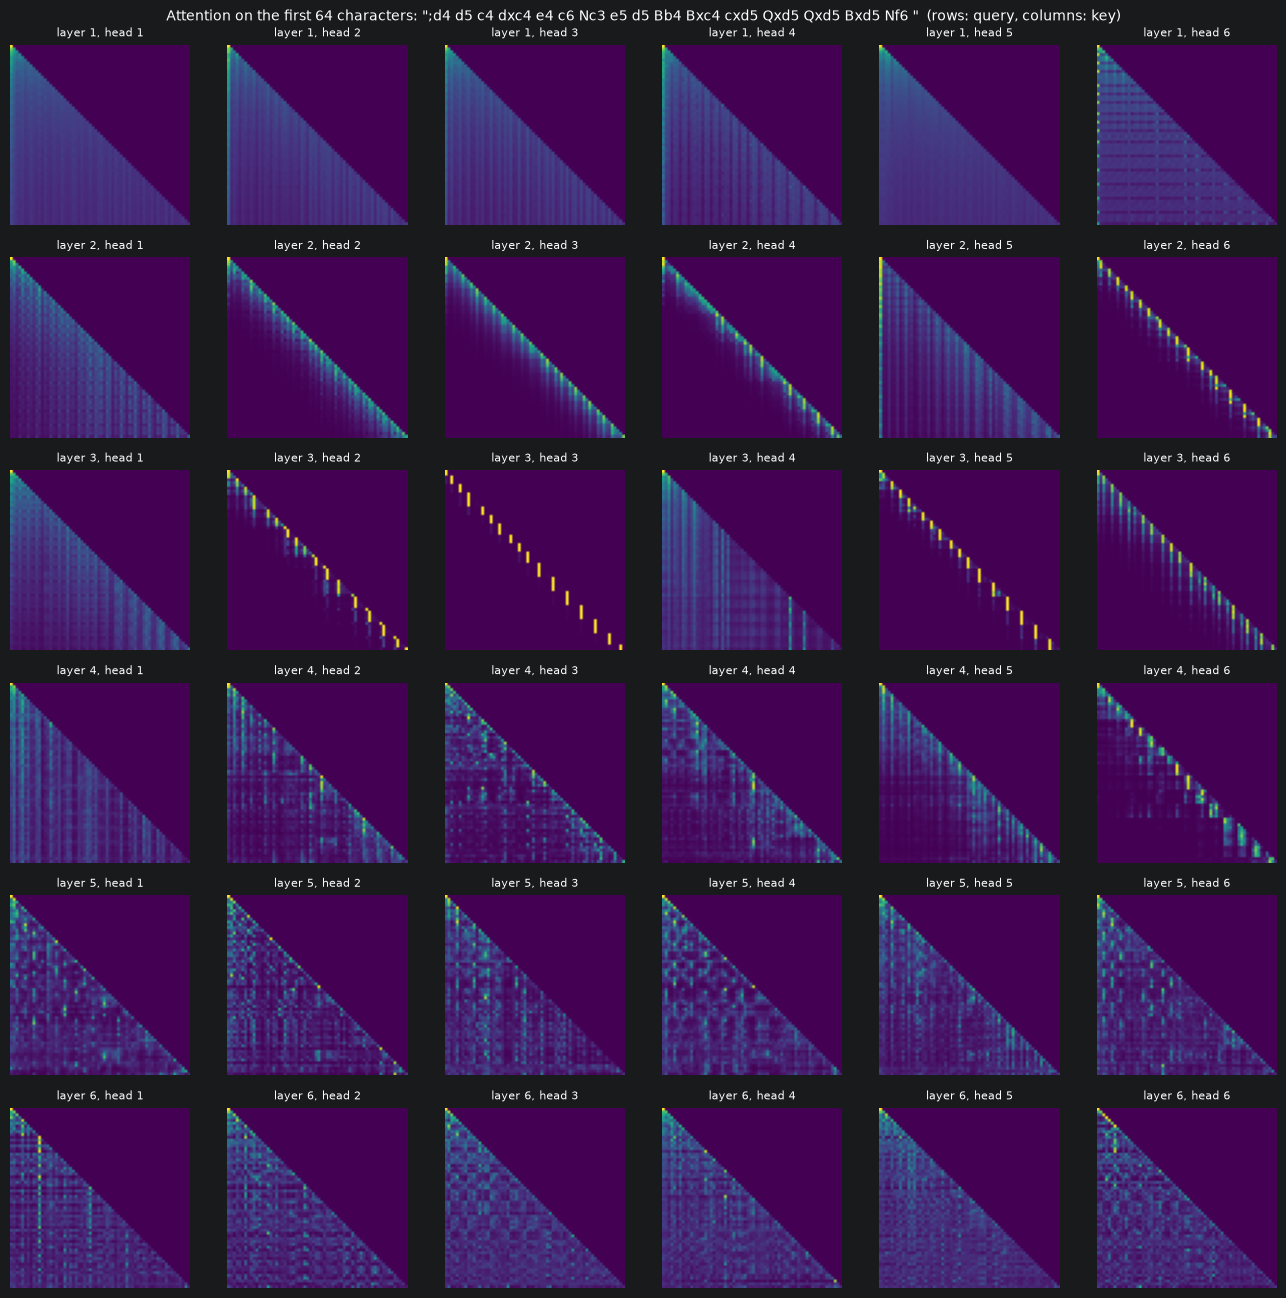

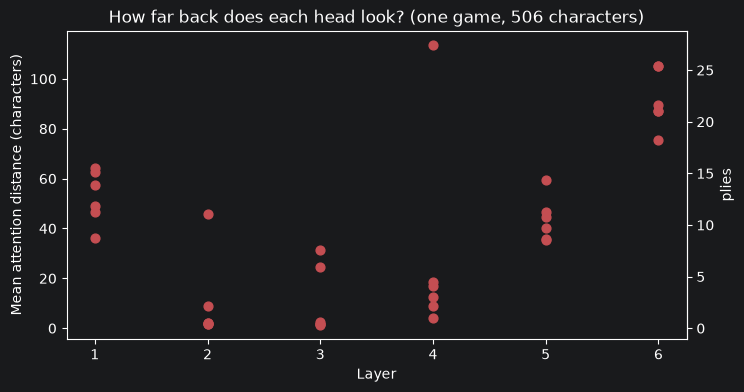

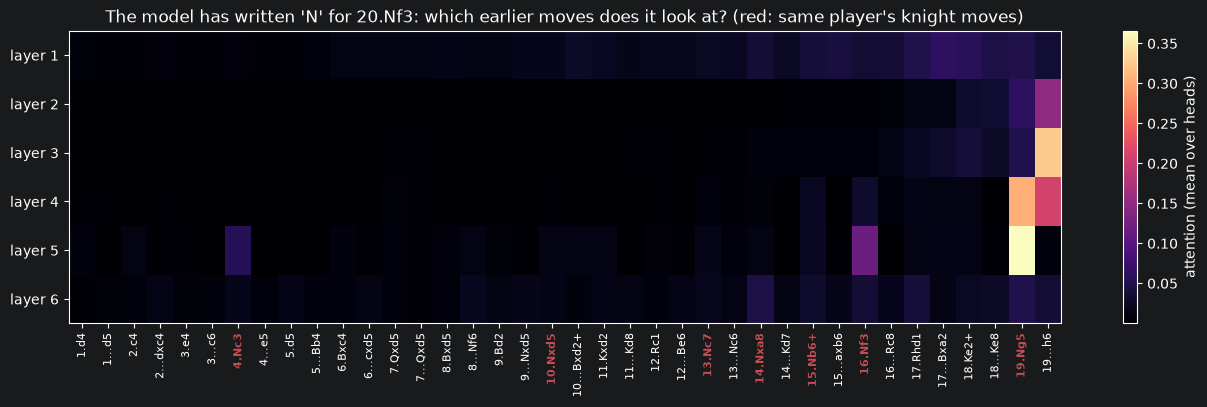

Same-piece attention ratio over 11,567 queries (1 = no preference):
  layer 1: mean over heads 1.44 | best head 1.90 (head 4)
  layer 2: mean over heads 1.04 | best head 1.84 (head 5)
  layer 3: mean over heads 1.00 | best head 1.89 (head 1)
  layer 4: mean over heads 3.14 | best head 7.28 (head 4)
  layer 5: mean over heads 6.17 | best head 8.94 (head 1)
  layer 6: mean over heads 1.71 | best head 2.15 (head 6)


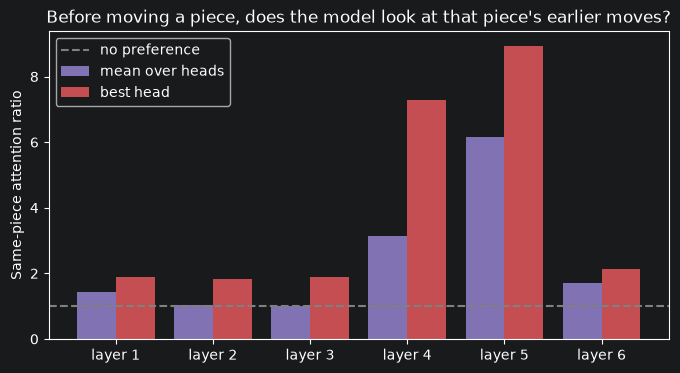

GPT(
  (tok_emb): Embedding(29, 192)
  (pos_emb): Embedding(512, 192)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (ln1): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=192, out_features=576, bias=True)
        (proj): Linear(in_features=192, out_features=192, bias=True)
      )
      (ln2): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
      (mlp): Sequential(
        (0): Linear(in_features=192, out_features=768, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=768, out_features=192, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=192, out_features=29, bias=True)
)

In [8]:
# --- ATTENTION MAPS ---

# Evaluation mode (no training here).
model.eval()


# Character spans of the moves of a game inside the text ';' + game.
def move_spans(moves):
    """Return a list of (start, end) character positions, one per move, in the text ';' + ' '.join(moves)."""

    # The first move starts right after ';'.
    pos = 1

    # Spans.
    spans = []

    # One span per move.
    for mv in moves:

        # Characters pos .. pos + len(mv) - 1.
        spans.append((pos, pos + len(mv)))

        # Skip the move and the following space.
        pos += len(mv) + 1

    # Return the spans.
    return spans


# Readable label of move number m: "12.Nf3" for White, "12...Nc6" for Black.
def move_label(moves, m):
    """Chess-style label with the move number."""

    # Move number, and dots depending on the side to move.
    return f"{m // 2 + 1}{'.' if m % 2 == 0 else '...'}{moves[m]}"


# Example game: the first validation game with at least 60 plies, fitting in one block, with a knight move between plies 20 and 45.
example_moves, query_move = None, None

# Search the validation games in order.
for g in val_games:

    # Its moves.
    mv = g.split()

    # Too short, or longer than one block.
    if len(mv) < 60 or len(g) + 1 > BLOCK:

        # Next game.
        continue

    # Its knight moves between plies 20 and 45.
    knight_moves = [m for m in range(20, 46) if mv[m][0] == "N"]

    # Found one.
    if knight_moves:

        # Keep the game and its last knight move in that range.
        example_moves, query_move = mv, knight_moves[-1]

        # Stop searching.
        break

# Text of the example game: ';' + moves.
example_text = SEP + " ".join(example_moves)

# Encoded and on the device, as a batch of one.
example_ids = torch.tensor([[stoi[c] for c in example_text]], device=device)

# One forward pass that also returns the attention maps of every layer: list of (1, H, T, T).
with torch.no_grad():

    # Logits are not needed here.
    _, _, example_attn = model(example_ids, return_attn=True)

# All maps on the CPU as one array: (layers, heads, T, T).
A = torch.stack([a[0] for a in example_attn]).cpu().numpy()

# --- VIEW 1: ALL HEADS ON THE FIRST 64 CHARACTERS ---

# Characters shown.
SHOW = 64

# Grid of layers x heads.
fig, axes = plt.subplots(N_LAYER, N_HEAD, figsize=(2.2 * N_HEAD, 2.2 * N_LAYER))

# One panel per head.
for l in range(N_LAYER):

    # Every head of layer l.
    for h in range(N_HEAD):

        # Attention of the first SHOW characters to the first SHOW characters; sqrt makes small weights visible.
        axes[l, h].imshow(np.sqrt(A[l, h, :SHOW, :SHOW]), cmap="viridis")

        # Title.
        axes[l, h].set_title(f"layer {l + 1}, head {h + 1}", fontsize=8)

        # No ticks.
        axes[l, h].axis("off")

# Overall title with the text shown.
fig.suptitle(f"Attention on the first {SHOW} characters: \"{example_text[:SHOW]}\"  (rows: query, columns: key)", fontsize=10)

# Layout.
plt.tight_layout()

# Render.
plt.show()

# --- VIEW 2: MEAN ATTENTION DISTANCE OF EVERY HEAD ---

# Length of the example.
T_ex = A.shape[-1]

# Distance t - j for every pair (query t, key j); negative values are masked anyway (weight 0).
distance = np.arange(T_ex)[:, None] - np.arange(T_ex)[None, :]

# Mean distance of each head: sum over keys of alpha * distance, averaged over queries -> (layers, heads).
mean_distance = (A * np.clip(distance, 0, None)).sum(axis=-1).mean(axis=-1)

# One panel.
fig, ax = plt.subplots(figsize=(8, 4))

# One dot per head, at x = layer.
for l in range(N_LAYER):

    # The heads of layer l.
    ax.scatter([l + 1] * N_HEAD, mean_distance[l], color="#C44E52", s=40)

# x-axis: layers.
ax.set_xlabel("Layer")

# y-axis: characters.
ax.set_ylabel("Mean attention distance (characters)")

# Secondary y-axis in plies.
ax.secondary_yaxis("right", functions=(lambda c: c / 4.14, lambda p: p * 4.14)).set_ylabel("plies")

# Title.
ax.set_title(f"How far back does each head look? (one game, {T_ex} characters)")

# Render.
plt.show()

# --- VIEW 3: WHERE DOES THE MODEL LOOK WHEN IT MOVES A KNIGHT? ---

# Character spans of the moves.
spans = move_spans(example_moves)

# Position of the letter 'N' of the query move: there the model must predict where the knight goes.
q = spans[query_move][0]

# Previous moves shown: at most the last 40.
first = max(0, query_move - 40)

# Attention averaged over the heads, row q, summed over the characters of each previous move: (layers, moves).
move_attention = np.array([[A[l, :, q, s:e].mean(axis=0).sum() for (s, e) in spans[first:query_move]] for l in range(N_LAYER)])

# Previous moves of the same player's knights (same parity, starting with 'N').
same_piece = [(query_move - j) % 2 == 0 and example_moves[j][0] == "N" for j in range(first, query_move)]

# One wide panel.
fig, ax = plt.subplots(figsize=(16, 3.8))

# Heatmap layers x moves.
im = ax.imshow(move_attention, cmap="magma", aspect="auto")

# One tick per move, with its label.
ax.set_xticks(range(len(same_piece)), [move_label(example_moves, j) for j in range(first, query_move)], rotation=90, fontsize=8)

# Colour the same-piece moves in red.
for tick, red in zip(ax.get_xticklabels(), same_piece):

    # Red and bold for the knight moves of the same player.
    if red:

        # Highlight.
        tick.set_color("#C44E52")

        # Bold.
        tick.set_fontweight("bold")

# One tick per layer.
ax.set_yticks(range(N_LAYER), [f"layer {l + 1}" for l in range(N_LAYER)])

# Colour bar.
fig.colorbar(im, ax=ax, label="attention (mean over heads)")

# Title.
ax.set_title(f"The model has written 'N' for {move_label(example_moves, query_move)}: which earlier moves does it look at? (red: same player's knight moves)")

# Render.
plt.show()

# --- VIEW 4: IS IT SYSTEMATIC? SAME-PIECE ATTENTION OVER MANY GAMES ---

# Sum of the ratios, per layer and head.
ratio_sum = np.zeros((N_LAYER, N_HEAD))

# Number of queries used.
n_queries = 0

# Validation games used.
for g in val_games[:300]:

    # Moves of the game.
    mv = g.split()

    # Text that fits in one block (causal attention: the rows we need do not depend on later characters).
    text = (SEP + g)[:BLOCK]

    # Character spans of the moves.
    sp = move_spans(mv)

    # Queries: piece moves (N, B, R, Q, K) after ply 10, inside the block, with an earlier move of the same piece and player.
    queries = [m for m in range(10, len(mv)) if mv[m][0] in "NBRQK" and sp[m][0] < BLOCK
               and any(mv[j][0] == mv[m][0] for j in range(m % 2, m, 2))]

    # Nothing to measure in this game.
    if not queries:

        # Next game.
        continue

    # Forward pass with the attention maps.
    with torch.no_grad():

        # Encoded text as a batch of one.
        _, _, attn = model(torch.tensor([[stoi[c] for c in text]], device=device), return_attn=True)

    # Positions of the piece letters of the queries.
    q_pos = [sp[m][0] for m in queries]

    # Only the needed rows, moved to the CPU: (layers, heads, queries, T).
    rows = torch.stack([a[0][:, q_pos, :] for a in attn]).cpu().numpy()

    # Each query.
    for qi, m in enumerate(queries):

        # Mask of the characters of all previous moves.
        prev_mask = np.zeros(rows.shape[-1], dtype=bool)

        # Mask of the characters of the previous moves of the same piece and player.
        same_mask = np.zeros(rows.shape[-1], dtype=bool)

        # Previous moves.
        for j in range(m):

            # Characters of move j.
            s, e = sp[j]

            # Previous move.
            prev_mask[s:e] = True

            # Same piece letter and same player (same parity).
            if (m - j) % 2 == 0 and mv[j][0] == mv[m][0]:

                # Same-piece move.
                same_mask[s:e] = True

        # Share expected with uniform attention over the characters.
        base = same_mask.sum() / prev_mask.sum()

        # Attention on same-piece moves / attention on all previous moves, for every layer and head.
        share = rows[:, :, qi, same_mask].sum(-1) / (rows[:, :, qi, prev_mask].sum(-1) + 1e-9)

        # Accumulate the ratio.
        ratio_sum += share / base

        # One more query.
        n_queries += 1

# Average ratio per layer and head.
ratio = ratio_sum / n_queries

# Report.
print(f"Same-piece attention ratio over {n_queries:,} queries (1 = no preference):")

# One line per layer.
for l in range(N_LAYER):

    # Mean over the heads and best head.
    print(f"  layer {l + 1}: mean over heads {ratio[l].mean():.2f} | best head {ratio[l].max():.2f} (head {ratio[l].argmax() + 1})")

# One panel.
fig, ax = plt.subplots(figsize=(8, 4))

# Positions of the layers.
xl = np.arange(N_LAYER)

# Mean over the heads.
ax.bar(xl - 0.2, ratio.mean(axis=1), width=0.4, color="#8172B3", label="mean over heads")

# Best head.
ax.bar(xl + 0.2, ratio.max(axis=1), width=0.4, color="#C44E52", label="best head")

# Chance level.
ax.axhline(1, linestyle="--", color="gray", label="no preference")

# Layer labels.
ax.set_xticks(xl, [f"layer {l + 1}" for l in range(N_LAYER)])

# y-axis label.
ax.set_ylabel("Same-piece attention ratio")

# Title.
ax.set_title("Before moving a piece, does the model look at that piece's earlier moves?")

# Legend.
ax.legend()

# Render.
plt.show()

# Back to training mode (not needed any more, but keeps the model state consistent).
model.train()

## Step 7 — Fast generation with a KV cache, and the evaluation harness

### The problem
To sample a move, the model is called once per character, each time with the whole context. Without a trick, every call recomputes all the keys and values of all previous characters, in all 6 layers: generating $n$ characters after a context of $T$ costs about $O\big(n\,(T + n)\big)$ token computations instead of $O(n)$.

### The KV cache
In a causal Transformer the keys and values of a character **never change** once computed: later characters cannot influence earlier ones. So we store them, and for every new character we compute only its own $q, k, v$, append $k, v$ to the cache, and attend over the cache:

$$
K_{1:t+1} = \big[K_{1:t};\ k_{t+1}\big],
\qquad
V_{1:t+1} = \big[V_{1:t};\ v_{t+1}\big],
\qquad
y_{t+1} = \operatorname{softmax}\!\left(\frac{q_{t+1} K_{1:t+1}^\top}{\sqrt{d_k}}\right) V_{1:t+1}
$$

This plays the role of the LSTM state of v3, with one difference: the LSTM state has a **fixed size**, while the KV cache **grows** with the context, $2 \times L \times T \times d$ numbers: $2 \times 6 \times 512 \times 192 \approx 1.2$ million floats (4.7 MB) for a full block. In real LLMs with long contexts, the KV cache is often what limits how many users a GPU can serve at once.

The `GPTSampler` works like the `LSTMSampler`: if the new context extends the previous one, it feeds only the new characters with the cache; otherwise it starts again. If the context is longer than 512 characters, it re-reads the last 512 without cache (rare).
A check compares the cached computation with a full forward pass: the probabilities must be identical up to rounding errors.

### The rest of the harness
Identical to v3: the same 1,000 test positions (seed 123), legality, well-formedness, self-play and phase bins. The bigram is rebuilt; the v2 MLP and the v3 LSTM come from the shared results file (for v3 including the per-phase rates).

In [9]:
# --- GPT SAMPLER WITH A KV CACHE (on the CPU) ---

# Copy of the trained model on the CPU, in evaluation mode.
model_cpu = copy.deepcopy(model).to("cpu").eval()


# Next-character distribution with a KV cache.
class GPTSampler:
    """Callable object: context (list of indices) -> probabilities of the next character."""

    # Start with an empty cache.
    def __init__(self, model):

        # The (CPU) model.
        self.model = model

        # Context already processed.
        self.context = []

        # Keys and values of every layer for self.context; None means empty.
        self.cache = None

        # Logits produced after the last character processed.
        self.logits = None

    # Make the object callable like a function.
    @torch.no_grad()
    def __call__(self, context):

        # Context longer than the model can see: re-read its last BLOCK characters, without cache.
        if len(context) > BLOCK:

            # Forget the cache: positions would no longer match.
            self.context, self.cache = [], None

            # Full forward pass on the last BLOCK characters.
            logits, _, _ = self.model(torch.tensor([context[-BLOCK:]]))

            # Probabilities after the last character.
            return F.softmax(logits[0, -1], dim=0).numpy().astype(np.float64)

        # Length of the cached context.
        n = len(self.context)

        # If the new context does not start with the cached one, start again from scratch.
        if n == 0 or len(context) < n or context[:n] != self.context:

            # Reset the cache.
            self.context, self.cache, n = [], None, 0

        # Characters not processed yet.
        new = context[n:]

        # Process them, if any.
        if new:

            # Only the new characters go through the network; the cache provides the keys and values of the old ones.
            logits, self.cache, _ = self.model(torch.tensor([new]), cache=self.cache, use_cache=True)

            # Logits after the last new character.
            self.logits = logits[0, -1]

            # Remember the full context.
            self.context = list(context)

        # Softmax as float64 NumPy, for precise sampling.
        return F.softmax(self.logits, dim=0).numpy().astype(np.float64)


# The sampler used for evaluation.
gpt_next_char_probs = GPTSampler(model_cpu)

# --- CHECK: CACHE == FULL FORWARD PASS ---

# A context of 100 characters from a validation game.
check_ctx = [stoi[c] for c in (SEP + val_games[0])[:100]]

# Feed it in two parts: 60 characters, then 40 more using the cache.
gpt_next_char_probs(check_ctx[:60])

# Probabilities after the 100 characters, computed with the cache.
p_cached = gpt_next_char_probs(check_ctx)

# The same with one full forward pass.
with torch.no_grad():

    # Logits of the whole context.
    full_logits, _, _ = model_cpu(torch.tensor([check_ctx]))

# Probabilities after the last character.
p_full = F.softmax(full_logits[0, -1], dim=0).numpy()

# They must agree up to rounding errors.
print(f"KV cache check: max difference {np.abs(p_cached - p_full).max():.2e}")

# Stop if they do not.
assert np.allclose(p_cached, p_full, atol=1e-4)

# --- SPEED: WITH AND WITHOUT CACHE ---

# Generate 100 characters one by one after a 300-character context, both ways.
speed_ctx = [stoi[c] for c in (SEP + val_games[1])[:300]]

# Start time without cache.
t0 = time.perf_counter()

# Without cache: a full forward pass of the growing context for every new character.
with torch.no_grad():

    # 100 new characters (always the greedy choice, only the speed matters).
    ctx = list(speed_ctx)

    # One step per character.
    for _ in range(100):

        # Full forward pass.
        logits, _, _ = model_cpu(torch.tensor([ctx[-BLOCK:]]))

        # Most likely next character.
        ctx.append(int(logits[0, -1].argmax()))

# Time without cache.
t_no_cache = time.perf_counter() - t0

# Start time with cache.
t0 = time.perf_counter()

# With cache: a fresh sampler, the context is processed once, then one character at a time.
sampler = GPTSampler(model_cpu)

# Same 100 characters.
ctx = list(speed_ctx)

# One step per character.
for _ in range(100):

    # Probabilities via the cache.
    ctx.append(int(np.argmax(sampler(ctx))))

# Time with cache.
t_cache = time.perf_counter() - t0

# Report.
print(f"100 characters after a 300-character context: {t_no_cache:.2f}s without cache, {t_cache:.2f}s with cache "
      f"({t_no_cache / t_cache:.1f}x faster)")

# --- REBUILD THE v1 BIGRAM ---

# Training text as in v1.
bigram_ids = encode(SEP + SEP.join(train_games) + SEP)

# Pair counts.
counts = np.bincount(bigram_ids[:-1] * V + bigram_ids[1:], minlength=V * V).reshape(V, V)

# Smoothed probabilities.
P_count = (counts + 1.0) / (counts + 1.0).sum(axis=1, keepdims=True)


# Bigram next-character distribution.
def bigram_next_char_probs(context):
    """Row of the bigram table for the last character."""

    # Probability vector.
    return P_count[context[-1]]


# --- SAMPLING HELPERS ---

# Sample an index with temperature.
def sample_from(probs, temperature=1.0):
    """p^(1/T), renormalised, one draw."""

    # Sharpen or flatten.
    p = probs ** (1.0 / temperature)

    # Renormalise.
    p = p / p.sum()

    # Draw.
    return np.random.choice(len(p), p=p)


# Sample one move.
def sample_move(next_char_probs, context, temperature=1.0, max_len=10):
    """Return (move string, ended)."""

    # Copy of the context.
    context = list(context)

    # Characters of the move.
    move_chars = []

    # At most max_len characters.
    for _ in range(max_len):

        # Next character.
        nxt = sample_from(next_char_probs(context), temperature)

        # Space: end of move.
        if nxt == stoi[" "]:

            # Stop.
            break

        # Separator: end of game.
        if nxt == stoi[SEP]:

            # Signal the end.
            return "".join(move_chars), True

        # Part of the move.
        move_chars.append(itos[nxt])

        # Becomes context.
        context.append(nxt)

    # The move.
    return "".join(move_chars), False


# Context for a game prefix.
def prefix_context(moves):
    """';' + moves + trailing space."""

    # Text.
    text = SEP + " ".join(moves) + (" " if moves else "")

    # Encoded.
    return [stoi[c] for c in text]


# --- LEGALITY AND WELL-FORMEDNESS ---

# Legal move check.
def is_legal(board, san):
    """True for a legal move (False for illegal, malformed or null moves)."""

    # Try to parse.
    try:

        # Null move "--" is falsy.
        return bool(board.parse_san(san))

    # Parsing error.
    except ValueError:

        # Illegal.
        return False


# SAN grammar.
SAN_RE = re.compile(r"^(O-O(-O)?|[KQRBN][a-h]?[1-8]?x?[a-h][1-8]|[a-h](x[a-h])?[1-8](=[QRBN])?)[+#]?$")


# Well-formed check.
def is_well_formed(san):
    """True if the string matches the SAN grammar."""

    # Regex match.
    return SAN_RE.match(san) is not None


# --- THE SAME 1,000 TEST POSITIONS ---

# Same seed as v1 and v2.
pos_rng = random.Random(123)

# (moves, board) pairs.
test_positions = []

# Draw 1,000 positions.
while len(test_positions) < 1000:

    # Random test game.
    moves = pos_rng.choice(test_games).split()

    # Random cut point.
    k = pos_rng.randrange(len(moves))

    # Replay the prefix.
    board = chess.Board()

    # Each move.
    for m in moves[:k]:

        # Play it.
        board.push_san(m)

    # Store.
    test_positions.append((moves[:k], board))


# Evaluate a move proposer.
def evaluate_legality(propose_move):
    """Return (legal rate, well-formed rate, list of (k, legal, san))."""

    # Details.
    results = []

    # Each position.
    for moves, board in test_positions:

        # Proposed move.
        san = propose_move(moves)

        # Store.
        results.append((len(moves), is_legal(board, san), san))

    # Legal rate.
    legal_rate = np.mean([legal for _, legal, _ in results])

    # Well-formed rate.
    well_formed_rate = np.mean([is_well_formed(san) for _, _, san in results])

    # Return.
    return legal_rate, well_formed_rate, results


# Character model -> move proposer.
def char_model_proposer(next_char_probs, temperature=1.0):
    """moves -> sampled SAN."""

    # The proposer.
    def propose(moves):

        # Sample.
        san, _ = sample_move(next_char_probs, prefix_context(moves), temperature)

        # Return.
        return san

    # Return the function.
    return propose


# --- FREQUENCY BASELINE ---

# Training move counts.
train_move_counts = Counter(m for g in train_games for m in g.split())

# Distinct moves.
baseline_moves = list(train_move_counts.keys())

# Weights.
baseline_weights = list(train_move_counts.values())


# Random move with training frequencies.
def frequency_baseline(moves):
    """Weighted random move, ignoring the position."""

    # Draw.
    return random.choices(baseline_moves, weights=baseline_weights, k=1)[0]


# --- SELF-PLAY ---

# Both sides played by the model.
def self_play(next_char_probs, n_games=200, max_plies=300, temperature=1.0):
    """Return (legal plies per game, sequences)."""

    # Results.
    legal_plies, sequences = [], []

    # Each game.
    for _ in range(n_games):

        # New board.
        board = chess.Board()

        # Moves.
        moves = []

        # Play.
        while len(moves) < max_plies and not board.is_game_over():

            # Next move.
            san, ended = sample_move(next_char_probs, prefix_context(moves), temperature)

            # Stop on end token or illegal move.
            if ended or not is_legal(board, san):

                # Leave.
                break

            # Play.
            board.push_san(san)

            # Remember.
            moves.append(san)

        # Store plies.
        legal_plies.append(len(moves))

        # Store sequence.
        sequences.append(moves)

    # Return.
    return legal_plies, sequences


# Phase bins.
PHASE_BINS = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 10_000)]

# Labels.
PHASE_LABELS = ["0-9", "10-19", "20-39", "40-79", "80+"]


# Legal rate by phase.
def rate_by_phase(results):
    """One legal rate per phase bin."""

    # Values.
    rates = []

    # Each bin.
    for lo, hi in PHASE_BINS:

        # Legality in the bin.
        in_bin = [legal for k, legal, _ in results if lo <= k < hi]

        # Mean or NaN.
        rates.append(np.mean(in_bin) if in_bin else np.nan)

    # Return.
    return rates


# --- RESULTS OF THE PREVIOUS VERSIONS ---

# Shared results file.
RESULTS_PATH = DATA_DIR / "chessgpt_results.json"

# Load it.
results_all = json.loads(RESULTS_PATH.read_text())

# Legal rate of the v2 MLP.
legal_mlp = results_all["v2_mlp"]["legal_rate"]

# Self-play of the v2 MLP.
selfplay_mlp = results_all["v2_mlp"]["selfplay_mean_plies"]

# Per-phase legal rates of the v2 MLP, read off the v2 chart (approximate: they were not saved).
V2_PHASE = [0.78, 0.42, 0.26, 0.21, 0.24]

# Legal rate of the v3 LSTM.
legal_lstm = results_all["v3_lstm"]["legal_rate"]

# Self-play of the v3 LSTM.
selfplay_lstm = results_all["v3_lstm"]["selfplay_mean_plies"]

# Per-phase legal rates of the v3 LSTM (saved by v3).
V3_PHASE = results_all["v3_lstm"]["phase_legal_rates"]

KV cache check: max difference 0.00e+00
100 characters after a 300-character context: 1.27s without cache, 0.17s with cache (7.3x faster)


## Step 8 — Results: does attention make moves legal?

**Expected:** if attention really lets the model re-read the moves that placed every piece, the gain over the LSTM should be largest in the **middle game** (plies 20–79), where the LSTM was at 35–43%.

Evaluation time: 10s

model                  well-formed   legal
frequency baseline          100.0%   11.2%
v1 bigram                    94.1%   10.2%
v2 MLP (saved)              100.0%   36.9%
v3 LSTM (saved)             100.0%   55.4%
v4 GPT                       99.8%   56.9%

Self-play (200 games, 8s): GPT mean 10.46 legal plies (median 10, max 25)   (v2 MLP: 6.58, v3 LSTM: 10.43)

Legal rate by phase:        0-9   10-19   20-39   40-79     80+
  v3 LSTM (saved)         91.1%   75.9%   42.7%   34.6%   48.6%
  v4 GPT                  94.7%   73.8%   46.5%   40.4%   29.2%


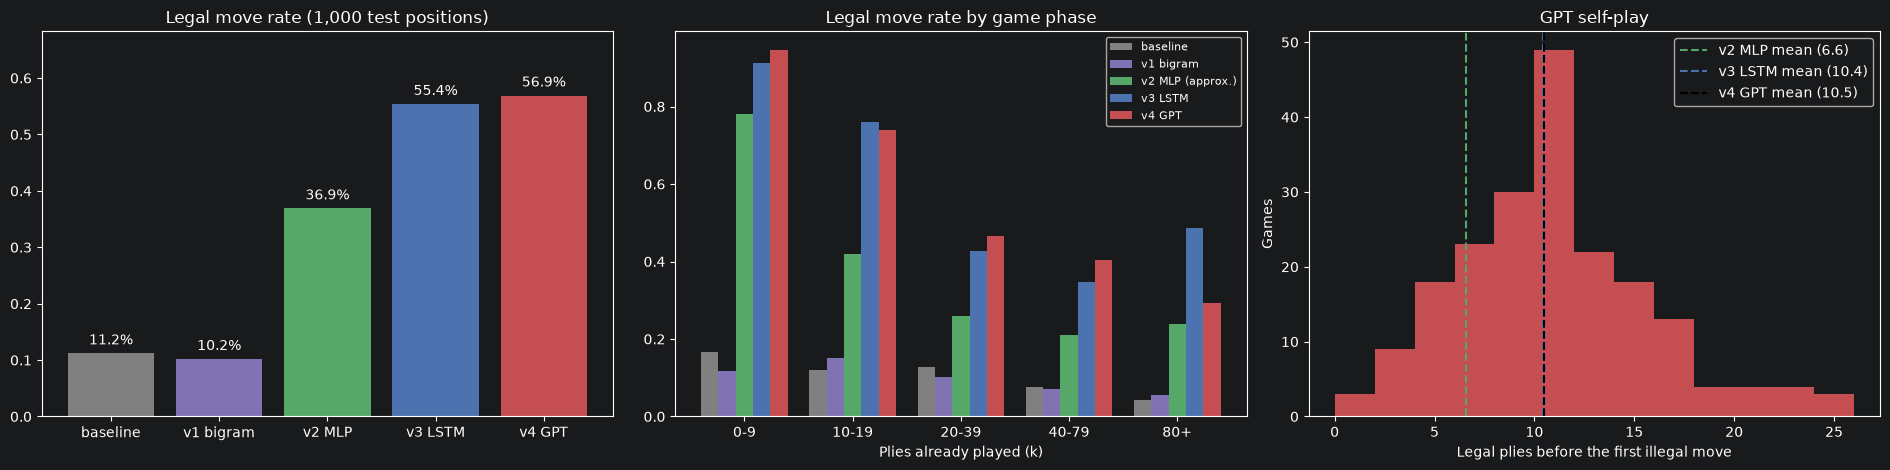

In [10]:
# --- NEXT-MOVE LEGALITY ON THE 1,000 TEST POSITIONS ---

# Fixed seeds.
np.random.seed(0)

# Same for Python's random module.
random.seed(0)

# Start time.
start = time.perf_counter()

# Baseline.
legal_base, wf_base, res_base = evaluate_legality(frequency_baseline)

# Bigram.
legal_bigram, wf_bigram, res_bigram = evaluate_legality(char_model_proposer(bigram_next_char_probs))

# GPT.
legal_gpt, wf_gpt, res_gpt = evaluate_legality(char_model_proposer(gpt_next_char_probs))

# Evaluation time.
print(f"Evaluation time: {time.perf_counter() - start:.0f}s\n")

# Header.
print(f"{'model':<22}{'well-formed':>12}{'legal':>8}")

# Baseline.
print(f"{'frequency baseline':<22}{wf_base:>12.1%}{legal_base:>8.1%}")

# Bigram.
print(f"{'v1 bigram':<22}{wf_bigram:>12.1%}{legal_bigram:>8.1%}")

# MLP (saved results).
print(f"{'v2 MLP (saved)':<22}{results_all['v2_mlp']['well_formed_rate']:>12.1%}{legal_mlp:>8.1%}")

# LSTM (saved results).
print(f"{'v3 LSTM (saved)':<22}{results_all['v3_lstm']['well_formed_rate']:>12.1%}{legal_lstm:>8.1%}")

# GPT.
print(f"{'v4 GPT':<22}{wf_gpt:>12.1%}{legal_gpt:>8.1%}")

# --- SELF-PLAY ---

# Start time.
start = time.perf_counter()

# GPT self-play.
gpt_plies, gpt_sequences = self_play(gpt_next_char_probs)

# Report.
print(f"\nSelf-play (200 games, {time.perf_counter() - start:.0f}s): GPT mean {np.mean(gpt_plies):.2f} legal plies "
      f"(median {np.median(gpt_plies):.0f}, max {max(gpt_plies)})   (v2 MLP: {selfplay_mlp:.2f}, v3 LSTM: {selfplay_lstm:.2f})")

# Phase rates of the GPT.
phase_gpt = rate_by_phase(res_gpt)

# Phase table.
print("\nLegal rate by phase:   " + "".join(f"{label:>8}" for label in PHASE_LABELS))

# LSTM row.
print("  v3 LSTM (saved)      " + "".join(f"{r:>8.1%}" for r in V3_PHASE))

# GPT row.
print("  v4 GPT               " + "".join(f"{r:>8.1%}" for r in phase_gpt))

# --- PLOTS ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 4.8))

# Model names.
names = ["baseline", "v1 bigram", "v2 MLP", "v3 LSTM", "v4 GPT"]

# Legal rates.
legal_rates = [legal_base, legal_bigram, legal_mlp, legal_lstm, legal_gpt]

# One bar per model.
bars = ax1.bar(names, legal_rates, color=["gray", "#8172B3", "#55A868", "#4C72B0", "#C44E52"])

# Value labels.
for bar, value in zip(bars, legal_rates):

    # Label above the bar.
    ax1.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.1%}", ha="center", va="bottom")

# Room above the bars.
ax1.set_ylim(0, max(legal_rates) * 1.2)

# Title.
ax1.set_title("Legal move rate (1,000 test positions)")

# Phase chart.
xp = np.arange(len(PHASE_LABELS))

# Baseline.
ax2.bar(xp - 0.32, rate_by_phase(res_base), width=0.16, color="gray", label="baseline")

# Bigram.
ax2.bar(xp - 0.16, rate_by_phase(res_bigram), width=0.16, color="#8172B3", label="v1 bigram")

# MLP (approximate values from v2).
ax2.bar(xp, V2_PHASE, width=0.16, color="#55A868", label="v2 MLP (approx.)")

# LSTM (saved by v3).
ax2.bar(xp + 0.16, V3_PHASE, width=0.16, color="#4C72B0", label="v3 LSTM")

# GPT.
ax2.bar(xp + 0.32, phase_gpt, width=0.16, color="#C44E52", label="v4 GPT")

# Bin labels.
ax2.set_xticks(xp, PHASE_LABELS)

# x-axis label.
ax2.set_xlabel("Plies already played (k)")

# Title.
ax2.set_title("Legal move rate by game phase")

# Legend.
ax2.legend(fontsize=8)

# Self-play histogram, bins of 2 plies.
ax3.hist(gpt_plies, bins=range(0, max(gpt_plies) + 3, 2), color="#C44E52")

# v2 reference.
ax3.axvline(selfplay_mlp, linestyle="--", color="#55A868", label=f"v2 MLP mean ({selfplay_mlp:.1f})")

# v3 reference.
ax3.axvline(selfplay_lstm, linestyle="--", color="#4C72B0", label=f"v3 LSTM mean ({selfplay_lstm:.1f})")

# GPT mean.
ax3.axvline(np.mean(gpt_plies), linestyle="--", color="black", label=f"v4 GPT mean ({np.mean(gpt_plies):.1f})")

# x-axis label.
ax3.set_xlabel("Legal plies before the first illegal move")

# y-axis label.
ax3.set_ylabel("Games")

# Title.
ax3.set_title("GPT self-play")

# Legend.
ax3.legend()

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 9 — Temperature, examples and the longest game

Same analyses as v2 and v3: legality at lower temperatures, a few commented examples (the same 10 test positions as before, so you can compare the answers with v3), and the board at the end of the longest legal self-play game.

 temperature  well-formed   legal
         1.0        99.8%   56.4%
         0.8       100.0%   62.1%
         0.5       100.0%   64.7%

Examples (last moves of the context -> GPT move):
  ply  34 | ...Bd4 Qe7 Qa5 b6               -> Qxa7     legal
  ply  49 | ...Qg6 Qxd7+ Qf7 Re7            -> Qd7      well-formed but illegal
  ply  17 | ...d6 Nf3 d5 cxd5               -> cxd5     legal
  ply   9 | ...Bc5 Nf3 d6 d4                -> b6       legal
  ply  34 | ...Ng5 Bc5+ Bf2 Qg3+            -> Kh1      legal
  ply  42 | ...gxf4 gxf4 Kf3 fxe3           -> Rd4      well-formed but illegal
  ply   1 | ...g3                           -> e6       legal
  ply   8 | ...e4 Bb4 a3 Bc5                -> b4       legal
  ply  42 | ...Qf4 Bc6 Nh4 Nh5              -> Ng6      legal
  ply  31 | ...Ng4 Rh1 Kh8 Bd2              -> Qe6      legal

Longest legal GPT self-play game (25 plies): d4 d5 b4 Nc6 a3 e5 e3 Bf5 Bd3 Be7 Bxe4 dxe4 Nc3 Nf6 a4 h6 b5 Nd5 Nf3 Nxf4 Qe2 Nd5 O-O exd4 Nxd4


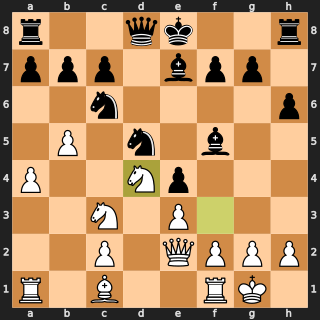

In [11]:
# --- TEMPERATURE SWEEP ---

# Header.
print(f"{'temperature':>12}{'well-formed':>13}{'legal':>8}")

# Three temperatures.
for T in [1.0, 0.8, 0.5]:

    # Same seed for each temperature.
    np.random.seed(0)

    # Evaluate.
    legal_T, wf_T, _ = evaluate_legality(char_model_proposer(gpt_next_char_probs, temperature=T))

    # Row.
    print(f"{T:>12.1f}{wf_T:>13.1%}{legal_T:>8.1%}")

# --- EXAMPLES ---

# Title.
print("\nExamples (last moves of the context -> GPT move):")

# First 10 test positions.
for (moves, board), (k, legal, san) in zip(test_positions[:10], res_gpt[:10]):

    # Verdict.
    verdict = "legal" if legal else ("well-formed but illegal" if is_well_formed(san) else "malformed")

    # Last 4 moves of the context.
    tail = " ".join(moves[-4:]) if moves else "(start)"

    # Print.
    print(f"  ply {k:3d} | ...{tail:<28} -> {san:<8} {verdict}")

# --- LONGEST LEGAL SELF-PLAY GAME ---

# Index of the longest game.
best = int(np.argmax(gpt_plies))

# Its moves.
best_moves = gpt_sequences[best]

# Print them.
print(f"\nLongest legal GPT self-play game ({len(best_moves)} plies):", " ".join(best_moves))

# Replay it.
board = chess.Board()

# Each move.
for m in best_moves:

    # Play.
    board.push_san(m)

# Draw the final position.
display(SVG(chess.svg.board(board, lastmove=board.peek() if best_moves else None, size=320)))

## Step 10 — Save the results

The v4 results are added to the shared file, with the per-phase legal rates, for the final comparison of v6.

In [12]:
# --- SAVE THE RESULTS OF v4 ---

# Results of the GPT.
results_all["v4_gpt"] = {
    # Validation bits per character.
    "val_bpc": float(bpc_gpt),
    # Legal move rate at temperature 1.
    "legal_rate": float(legal_gpt),
    # Well-formed rate.
    "well_formed_rate": float(wf_gpt),
    # Mean legal plies in self-play.
    "selfplay_mean_plies": float(np.mean(gpt_plies)),
    # Legal rate in each phase bin.
    "phase_legal_rates": [float(r) for r in phase_gpt],
    # Number of parameters.
    "params": int(n_params),
}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show it.
print(json.dumps(results_all, indent=2))

{
  "baseline": {
    "legal_rate": 0.112,
    "well_formed_rate": 1.0
  },
  "v1_bigram": {
    "val_bpc": 2.4304427985659216,
    "legal_rate": 0.102,
    "selfplay_mean_plies": 0.305,
    "well_formed_rate": 0.941
  },
  "v2_mlp": {
    "val_bpc": 1.5581939788328818,
    "legal_rate": 0.369,
    "well_formed_rate": 1.0,
    "selfplay_mean_plies": 6.58,
    "params": 475349
  },
  "v3_lstm": {
    "val_bpc": 1.2579778486516928,
    "legal_rate": 0.554,
    "well_formed_rate": 1.0,
    "selfplay_mean_plies": 10.425,
    "phase_legal_rates": [
      0.9112426035502958,
      0.7591623036649214,
      0.4270833333333333,
      0.3464285714285714,
      0.4861111111111111
    ],
    "params": 1883869
  },
  "v4_gpt": {
    "val_bpc": 1.282307804312627,
    "legal_rate": 0.569,
    "well_formed_rate": 0.998,
    "selfplay_mean_plies": 10.455,
    "phase_legal_rates": [
      0.9467455621301775,
      0.7382198952879581,
      0.4652777777777778,
      0.4035714285714286,
      0.291666666

## Results and conclusions

### Summary
| Model | Parameters | Context | Val bits/char | Legal move rate | Self-play plies |
|---|---|---|---|---|---|
| Frequency baseline | — | none | — | 11.2% | — |
| v1 Bigram | 841 | 1 character | 2.430 | 10.2% | 0.31 |
| v2 MLP + embeddings | 475,349 | 16 characters | 1.558 | 36.9% | 6.58 |
| v3 LSTM | 1,883,869 | whole game, in a 384-number state | **1.258** | 55.4% | 10.43 |
| **v4 GPT** | **2,779,037** | **512 characters, re-read directly** | 1.282 | **56.9%** | **10.46** |

The GPT reaches the LSTM, but does not clearly beat it yet: slightly worse in bits per character (1.282 against 1.258), slightly better in legal move rate (+1.5 points, which is within the noise: the standard error over 1,000 positions is about 1.6 points). The real news is in **how** it works (attention maps), not yet in the final numbers.

### Training: the GPT is undertrained
- The validation loss was still dropping quickly at the end (1.316 → 1.304 in the last 250 steps): more training would help.
- The comparison with the LSTM is not equal in data: the GPT saw about **49 million characters** (3,000 steps × 16,384), the LSTM about **180 million** (two runs of 3 epochs over 30 million characters).
- The training loss stays slightly **above** the validation loss. This is not underfitting: training windows start at random points, often in the middle of a game, so their first predictions have no context; validation games are always read from their first character.
- The gradient norm (0.42–0.45) is higher than for the LSTM (about 0.1), but far below the clipping threshold.
- Gradient accumulation worked: 4 micro-batches of 8 windows on an 8 GB Mac, about 1 second per step.

### Legal move rate by game phase
| Plies already played | Positions | v3 LSTM | v4 GPT | Difference |
|---|---|---|---|---|
| 0–9 | 169 | 91.1% | **94.7%** | +3.6 |
| 10–19 | 191 | **75.9%** | 73.8% | −2.1 |
| 20–39 | 288 | 42.7% | **46.5%** | +3.8 |
| 40–79 | 280 | 34.6% | **40.4%** | +5.8 |
| 80+ | 72 | **48.6%** | 29.2% | −19.4 |

- In the **middle game** (plies 20–79), where the LSTM was weakest, the GPT is better: +3.8 and +5.8 points. With 280 positions the standard error is about 3 points, so the +5.8 is suggestive but not conclusive.
- In **long games** (80+) the GPT is much worse. This bin has only 72 positions (standard error about 6 points per model), so part of the gap may be noise. One possible cause: beyond about 124 plies the beginning of the game falls outside the 512-character window, while the LSTM never forgets it completely. The loss curve also rises slightly after the context limit.

### Loss along the game
The shape is the same as for the LSTM: about 0.82 bits per character in the opening, a peak of about 1.52 around ply 50, then a decrease towards the endgame. After the 512-character context limit the loss rises again slightly (1.24 → 1.27), consistent with the sliding window losing the start of the game.

### Attention maps: what the model learned
**All heads (view 1)**: clear specialisations emerged without any supervision:
- layers 2–3: heads that read the **previous character** (a sharp line just below the diagonal) and heads with **periodic stripes**, which look at a fixed point of every move, such as the space that precedes it;
- layers 4–6: scattered, content-dependent lookups far back in the game.

**Attention distance (view 2)**: layers 2–4 are mostly local (a few characters); layer 6 looks furthest back, about 75–105 characters on average (18–25 plies).

**One concrete example (view 3)**: the model has written `N` for **20.Nf3**, and must now say where the knight goes:
- layer 5 looks almost exclusively at **19.Ng5** and **16.Nf3**: exactly the moves that tell where this knight is (it went to f3 on move 16, then to g5 on move 19, and now it is about to come back to f3);
- layers 2–4 look at **19…h6**, the move just played. It is tempting to read it as "h6 attacks the knight on g5, so the knight retreats", but this is our interpretation, not something we have measured.

**Systematic measurement (view 4)**: over **11,567 piece moves** in 300 validation games:

| Layer | Same-piece ratio, mean over heads | Best head |
|---|---|---|
| 1 | 1.44 | 1.90 |
| 2 | 1.04 | 1.84 |
| 3 | 1.00 | 1.89 |
| 4 | 3.14 | 7.28 |
| **5** | **6.17** | **8.94** |
| 6 | 1.71 | 2.15 |

Before moving a piece, **layers 4 and 5 look at the earlier moves of the same piece type and the same player 6 to 9 times more than chance**. Nobody told the model what a piece is or that it should track it: it discovered by itself that, to know where a knight can go, it must re-read the moves that brought it where it is. This is exactly what the LSTM could not do explicitly.

### KV cache
- The probabilities computed with the cache are **identical** to those of a full forward pass (maximum difference 0).
- Generating 100 characters after a 300-character context: **7.3 times faster** with the cache (0.17 s against 1.27 s on the CPU).

### Temperature, self-play and examples
| Temperature | Legal |
|---|---|
| 1.0 | 56.4% |
| 0.8 | 62.1% |
| 0.5 | **64.7%** |

- Self-play: mean 10.5 legal plies (as the LSTM), maximum **25**.
- Well-formed moves: 99.8%. Two moves out of 1,000 broke the SAN grammar, a small regression compared with v2 and v3.
- On the same 10 test positions as v3, the GPT gives 8 legal moves out of 10 (the LSTM gave 5).

### A measurement detail discovered here
The longest self-play game contains `Bxe4` with no piece on e4, and `Nxf4` with f4 empty. `python-chess`'s `parse_san` **ignores the capture sign `x`**, so these moves count as legal: the bishop really can go to e4, it just does not capture anything. The same leniency applied to all versions, so the comparison stays fair. But from v5 we will also measure a **strict** legality: the move must be legal *and* written exactly as `board.san(move)` would write it, with the correct `x`, `+` and `#`.

### Limits and next step
- Characters are a clumsy unit for chess: one move takes 2–7 tokens, the model must learn the spelling of every move, and 512 characters cover only about 124 plies.
- **v5, move-level tokens, a bigger GPT and linear probes:**
  - every move (`Nf3`, `exd5`, `O-O`) becomes **one token**, so one prediction is one move, and the same context covers many more plies;
  - a bigger model, trained longer;
  - **linear probes**: we will train a simple linear classifier on the hidden states of the GPT to answer "which piece is on e4?". If it succeeds, the model has built an **internal picture of the board** from text alone.